**Week 2: Retail Sales Visualization, Relationship Analysis & Business Insights**

**Dataset:** Superstore Sales Dataset (preprocessed in Week 1)

**Focus:** Univariate, bivariate and multivariate analysis; profit performance; discount impact; regional trends.

**Problem Statement**
Numerical summaries alone do not explain why certain product lines lose money or how regional discounting strategies affect revenue. Visual analysis is used to identify profit leaks and growth opportunities.

**Objectives**
- Perform univariate, bivariate and multivariate analysis of sales performance.
- Evaluate profit margins across categories, sub-categories and geographic regions.
- Analyze the relationship between discounts, sales volume and profitability.

**Expected Deliverables**
- Bar plots and box plots for sales and profit distributions.
- Discount-level analysis against profit margins.
- Correlation heatmap across numerical attributes.
- One-page business insights report.
Input: data/Superstore_Cleaned.csv exported from the Week 1 notebook.
Run the notebook from top to bottom. The notebook does not invent findings: observations should be written after reviewing the actual charts and computed tables.

1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Load the cleaned dataset

In [3]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/Superstore_Cleaned.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


3. Understand the dataset

In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales     

,Row ID,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,228.225854,3.791838,0.155385,28.673417
std,2942.898656,619.906839,2.228317,0.206249,232.465115
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,209.500000,5.000000,0.200000,29.297925
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000



Column Names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


4. Data preparation

In [5]:
# Convert numerical columns into numeric data types
numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records missing the required analysis values
df = df.dropna(subset=numeric_columns).copy()

# Clean categorical text columns
categorical_columns = [
    "Category", "Sub-Category", "Segment",
    "Region", "State", "City"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Calculate row-level profit margin
df["Profit Margin"] = np.where(
    df["Sales"] != 0,
    (df["Profit"] / df["Sales"]) * 100,
    np.nan
)

display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,33.75
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,-155.00
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,36.25
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,-23.75
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,25.00


5. Univariate analysis – Sales distribution

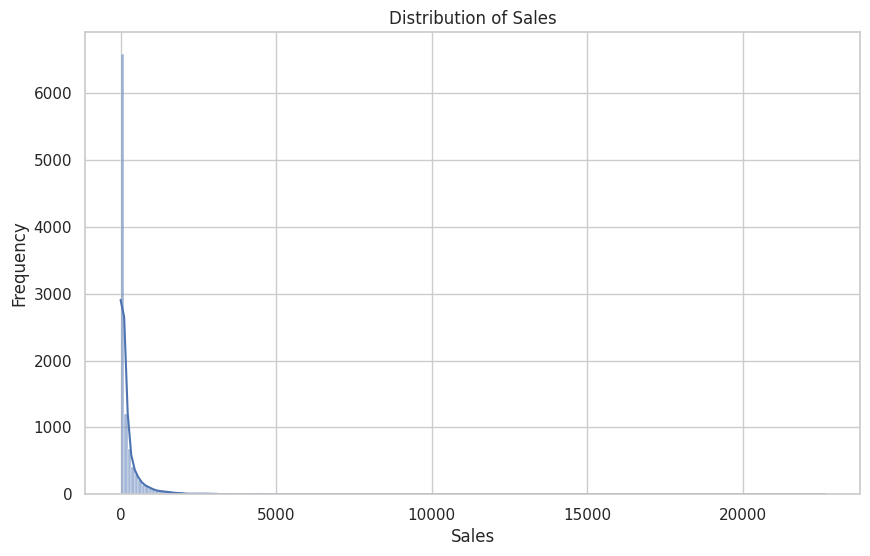

In [6]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="Sales", kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

6. Profit distribution

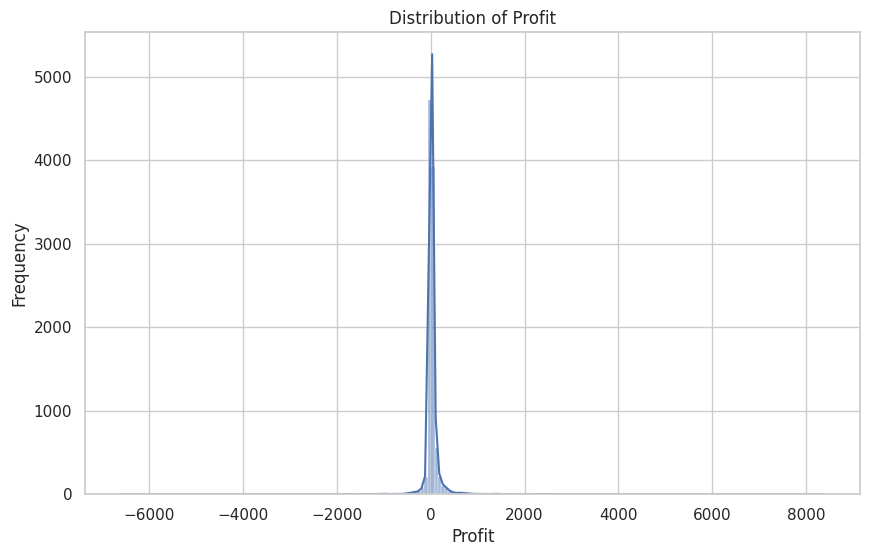

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="Profit", kde=True)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.show()

7. Quantity and discount distribution

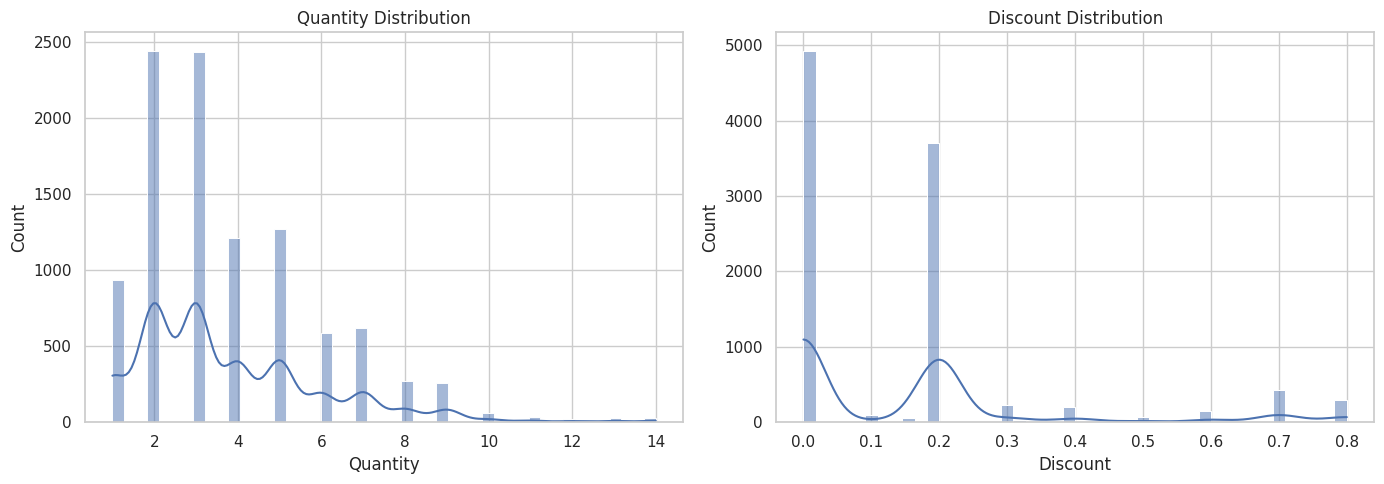

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="Quantity", kde=True, ax=axes[0])
axes[0].set_title("Quantity Distribution")

sns.histplot(data=df, x="Discount", kde=True, ax=axes[1])
axes[1].set_title("Discount Distribution")

plt.tight_layout()
plt.show()

8. Category-wise sales analysis

,Category,Sales
0,Furniture,754747.7613
1,Office Supplies,731893.3140
2,Technology,839893.2790


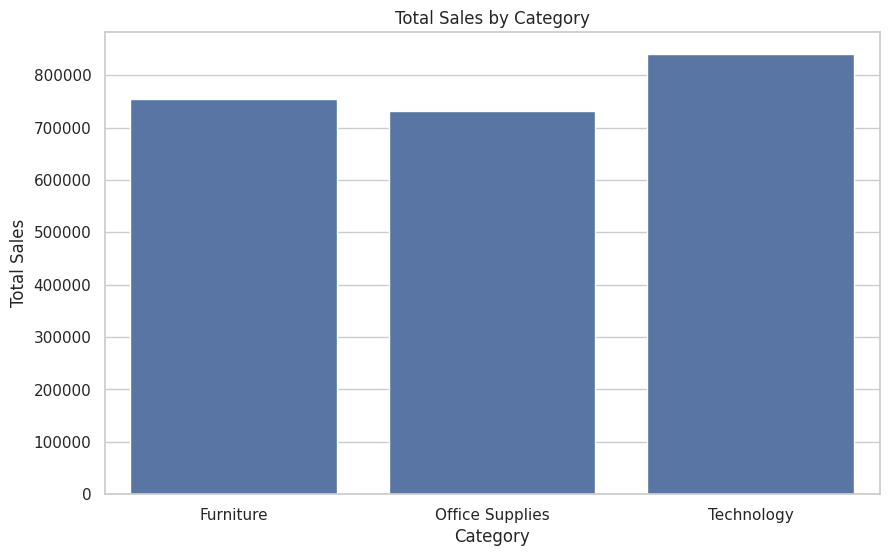

In [9]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .reset_index()
)

display(category_sales)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales"
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

9. Category-wise profit analysis

,Category,Profit
0,Furniture,19729.9956
1,Office Supplies,126023.4434
2,Technology,146543.3756


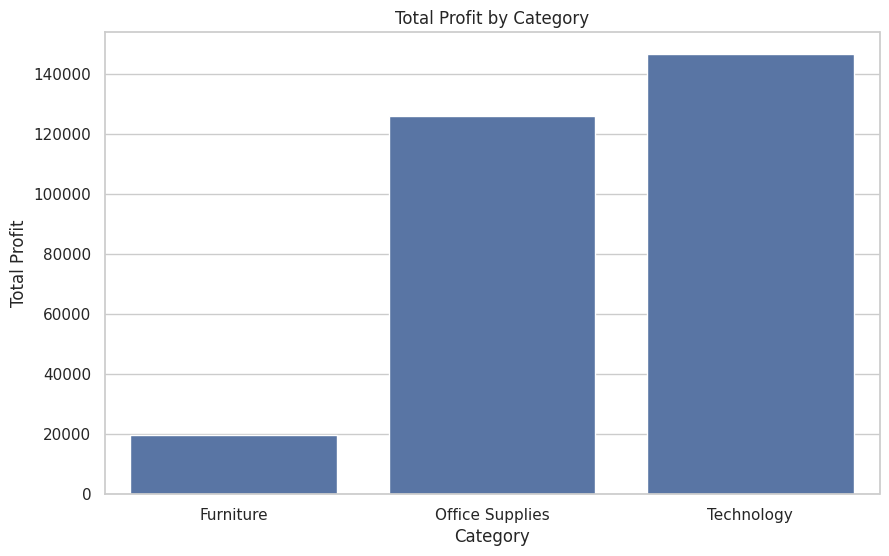

In [10]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .reset_index()
)

display(category_profit)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_profit,
    x="Category",
    y="Profit"
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()

10. Sub-category profit analysis

,Sub-Category,Profit
16,Tables,-17753.2061
4,Bookcases,-3632.0736
15,Supplies,-1171.3945
8,Fasteners,2428.6358
11,Machines,3461.9769
10,Labels,5572.7780
2,Art,6653.1962
7,Envelopes,6988.0247
9,Furnishings,13891.7430
1,Appliances,18329.4844


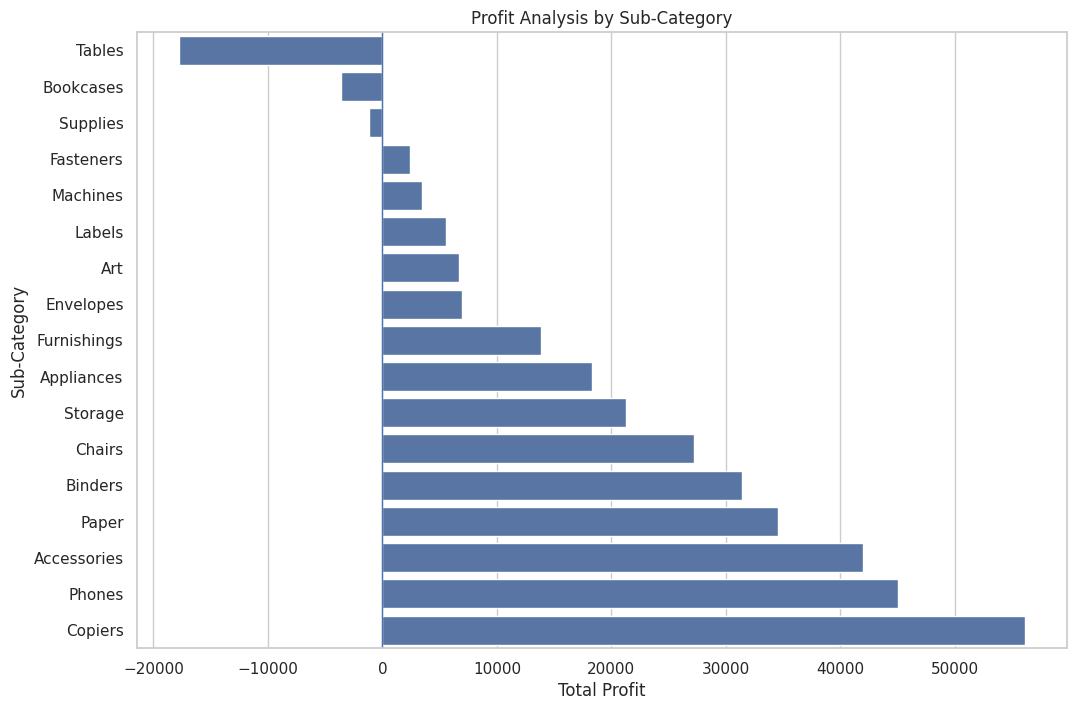

In [11]:
subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .reset_index()
    .sort_values(by="Profit", ascending=True)
)

display(subcategory_profit)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=subcategory_profit,
    x="Profit",
    y="Sub-Category"
)

plt.axvline(0, linewidth=1)

plt.title("Profit Analysis by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.show()

11. Box plot – Sales distribution by category

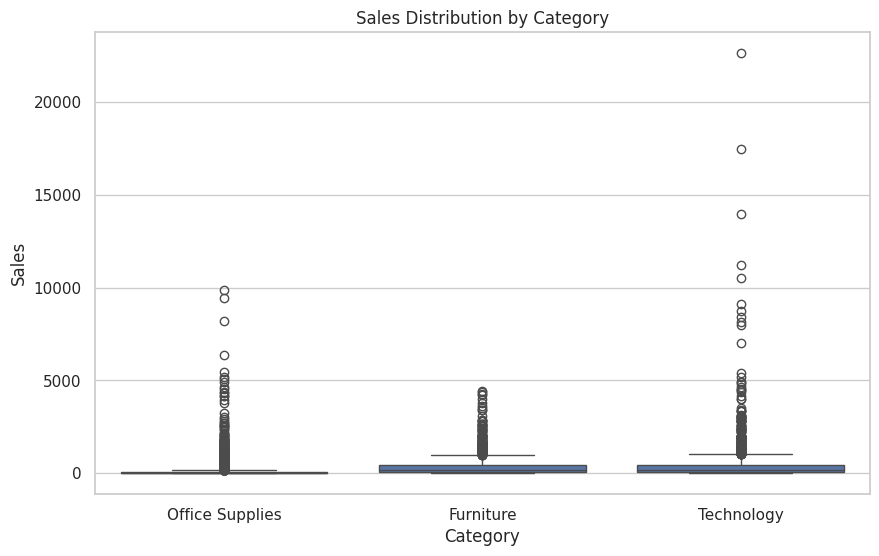

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Sales"
)

plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.show()

12. Box plot – Profit distribution by category

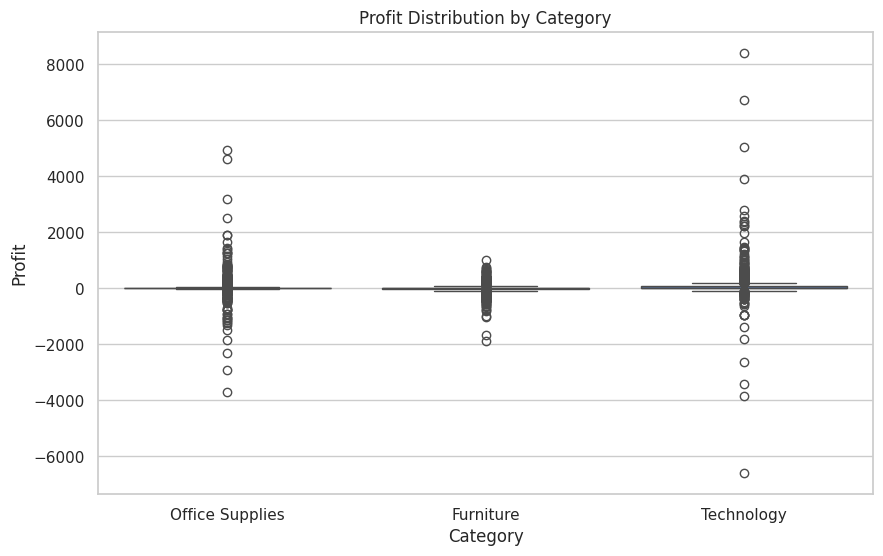

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Profit"
)

plt.title("Profit Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.show()

13. Discount impact on profitability

In [14]:
discount_analysis = (
    df.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Number_of_Orders=("Profit", "count")
    )
    .reset_index()
)

discount_analysis["Profit Margin"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"]
) * 100

display(discount_analysis.round(2))

,Discount,Total_Sales,Total_Profit,Average_Profit,Number_of_Orders,Profit Margin
0,0.00,1105323.79,326718.59,66.34,4925,29.56
1,0.10,54952.50,9099.97,94.79,96,16.56
2,0.15,27558.52,1418.99,27.29,52,5.15
3,0.20,773939.40,91079.95,24.58,3706,11.77
4,0.30,104474.07,-10513.45,-45.71,230,-10.06
5,0.32,14493.46,-2391.14,-88.56,27,-16.50
6,0.40,116497.76,-23086.37,-111.53,207,-19.82
7,0.45,5484.97,-2493.11,-226.65,11,-45.45
8,0.50,58918.54,-20506.43,-310.70,66,-34.80
9,0.60,7105.94,-6164.35,-41.37,149,-86.75


14. Discount vs profit margin visualization

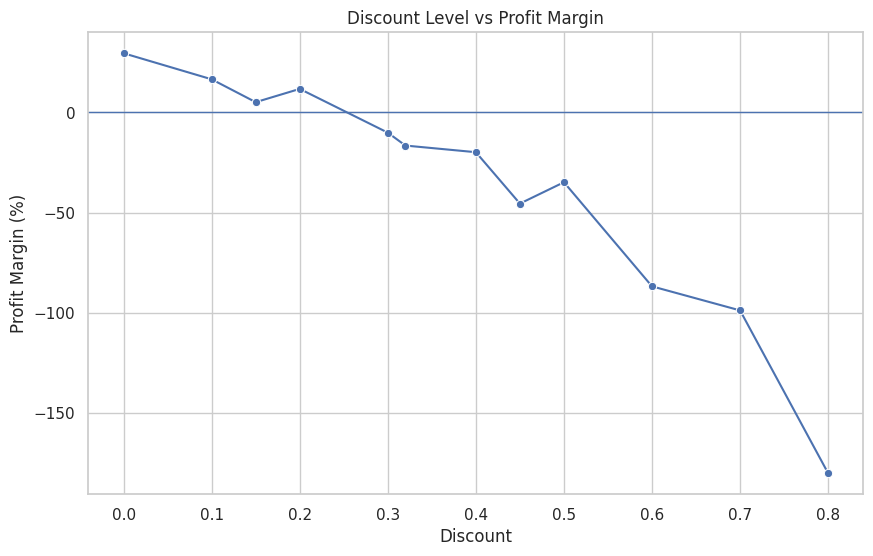

In [15]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=discount_analysis,
    x="Discount",
    y="Profit Margin",
    marker="o"
)

plt.axhline(0, linewidth=1)

plt.title("Discount Level vs Profit Margin")
plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")

plt.show()

15. Discount band analysis

In [16]:
bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.00]

labels = [
    "0%",
    ">0–10%",
    ">10–20%",
    ">20–30%",
    ">30–50%",
    ">50%"
]

df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

discount_band = (
    df.groupby("Discount Band", observed=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Transactions=("Profit", "count")
    )
    .reset_index()
)

discount_band["Profit Margin"] = (
    discount_band["Total_Profit"]
    / discount_band["Total_Sales"]
) * 100

display(discount_band.round(2))

,Discount Band,Total_Sales,Total_Profit,Average_Profit,Transactions,Profit Margin
0,0%,1105323.79,326718.59,66.34,4925,29.56
1,>0–10%,54952.50,9099.97,94.79,96,16.56
2,>10–20%,801497.92,92498.94,24.61,3758,11.54
3,>20–30%,104474.07,-10513.45,-45.71,230,-10.06
4,>30–50%,195394.73,-48477.05,-155.87,311,-24.81
5,>50%,64891.35,-77030.19,-88.14,874,-118.71


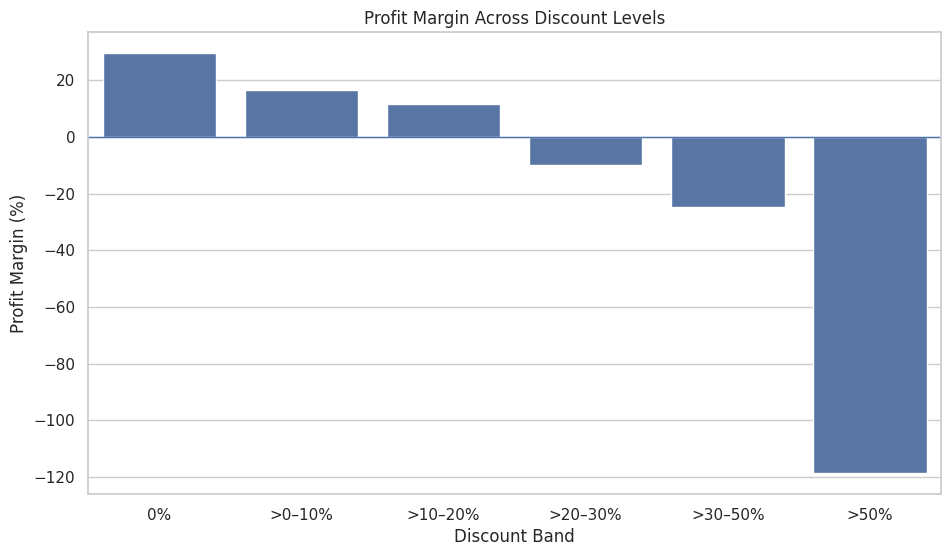

In [17]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=discount_band,
    x="Discount Band",
    y="Profit Margin"
)

plt.axhline(0, linewidth=1)

plt.title("Profit Margin Across Discount Levels")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")

plt.show()

16. Regional sales analysis

,Region,Sales
0,Central,503170.6728
1,East,691828.1680
2,South,391721.9050
3,West,739813.6085


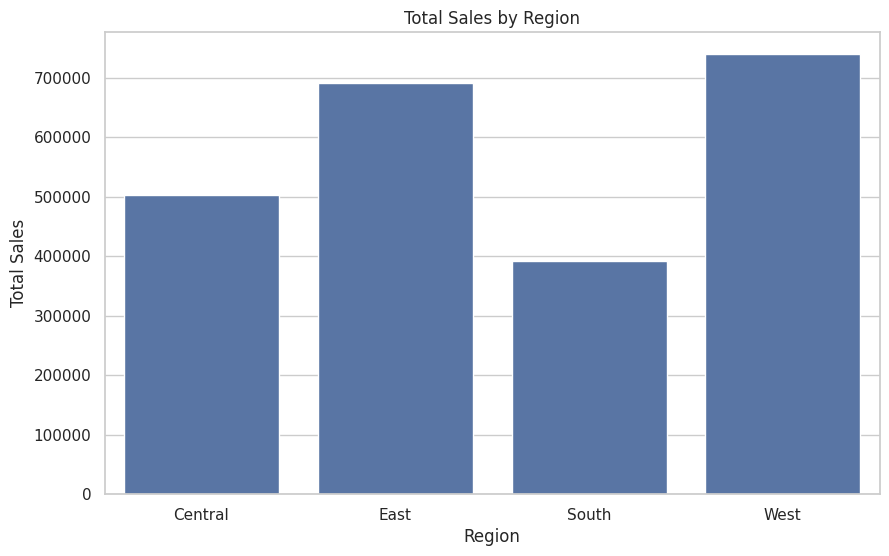

In [18]:
regional_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .reset_index()
)

display(regional_sales)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=regional_sales,
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

17. Regional profit analysis

,Region,Profit
0,Central,39865.3070
1,East,94883.2603
2,South,46749.4303
3,West,110798.8170


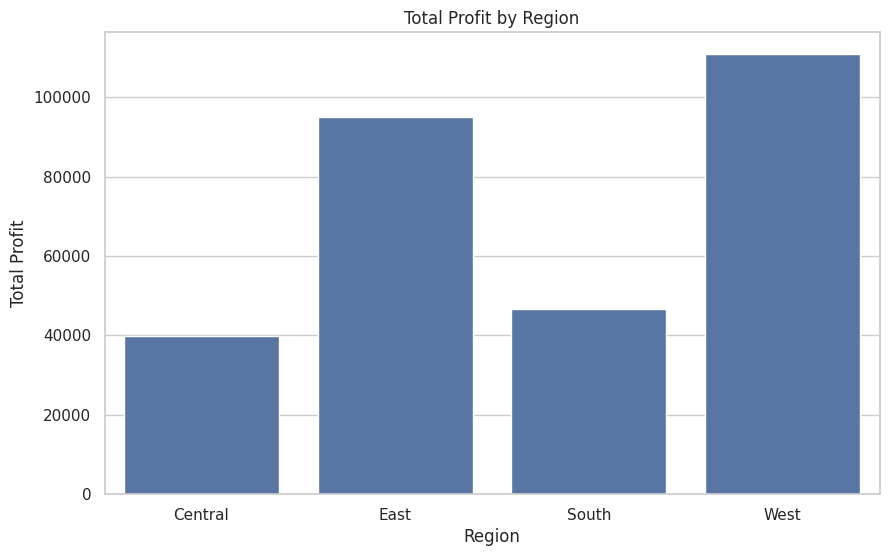

In [19]:
regional_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .reset_index()
)

display(regional_profit)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=regional_profit,
    x="Region",
    y="Profit"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.show()

18. Regional profit margin

In [20]:
region_summary = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_summary["Profit Margin"] = (
    region_summary["Total_Profit"]
    / region_summary["Total_Sales"]
) * 100

display(region_summary.round(2))

,Region,Total_Sales,Total_Profit,Profit Margin
0,Central,503170.67,39865.31,7.92
1,East,691828.17,94883.26,13.71
2,South,391721.90,46749.43,11.93
3,West,739813.61,110798.82,14.98


19. Correlation heatmap

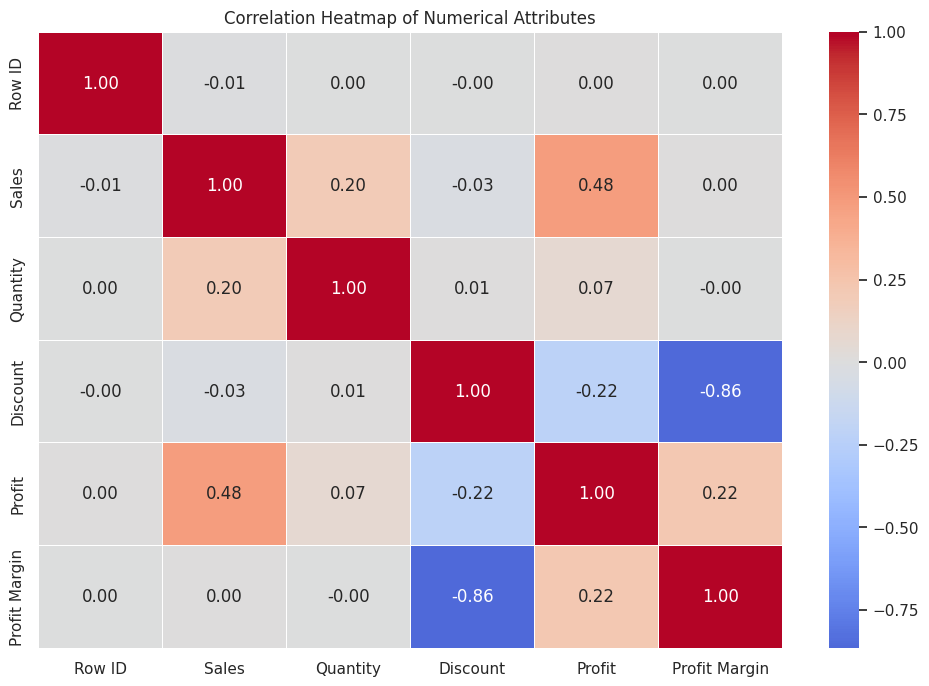

In [21]:
numeric_data = df.select_dtypes(include=np.number)

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Attributes")

plt.show()

20. Generate business summary tables

In [22]:
print("CATEGORY PERFORMANCE")
display(
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Profit", ascending=False)
)

print("TOP 5 PROFITABLE SUB-CATEGORIES")
display(subcategory_profit.tail(5))

print("BOTTOM 5 SUB-CATEGORIES")
display(subcategory_profit.head(5))

print("REGIONAL PERFORMANCE")
display(region_summary.sort_values("Total_Profit", ascending=False))

print("DISCOUNT PERFORMANCE")
display(discount_band.round(2))

CATEGORY PERFORMANCE


,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,839893.2790,146543.3756,7017
Office Supplies,731893.3140,126023.4434,23268
Furniture,754747.7613,19729.9956,8369


TOP 5 PROFITABLE SUB-CATEGORIES


,Sub-Category,Profit
3,Binders,31426.1003
12,Paper,34511.5070
0,Accessories,41936.6357
13,Phones,45050.8265
6,Copiers,56093.9365


BOTTOM 5 SUB-CATEGORIES


,Sub-Category,Profit
16,Tables,-17753.2061
4,Bookcases,-3632.0736
15,Supplies,-1171.3945
8,Fasteners,2428.6358
11,Machines,3461.9769


REGIONAL PERFORMANCE


,Region,Total_Sales,Total_Profit,Profit Margin
3,West,739813.6085,110798.8170,14.976585
1,East,691828.1680,94883.2603,13.714859
2,South,391721.9050,46749.4303,11.934342
0,Central,503170.6728,39865.3070,7.922820


DISCOUNT PERFORMANCE


,Discount Band,Total_Sales,Total_Profit,Average_Profit,Transactions,Profit Margin
0,0%,1105323.79,326718.59,66.34,4925,29.56
1,>0–10%,54952.50,9099.97,94.79,96,16.56
2,>10–20%,801497.92,92498.94,24.61,3758,11.54
3,>20–30%,104474.07,-10513.45,-45.71,230,-10.06
4,>30–50%,195394.73,-48477.05,-155.87,311,-24.81
5,>50%,64891.35,-77030.19,-88.14,874,-118.71


21. Export analysis results

In [23]:
import os

os.makedirs("reports", exist_ok=True)

category_sales.to_csv(
    "reports/category_sales.csv", index=False
)

category_profit.to_csv(
    "reports/category_profit.csv", index=False
)

subcategory_profit.to_csv(
    "reports/subcategory_profit.csv", index=False
)

regional_sales.to_csv(
    "reports/regional_sales.csv", index=False
)

regional_profit.to_csv(
    "reports/regional_profit.csv", index=False
)

region_summary.to_csv(
    "reports/regional_performance.csv", index=False
)

discount_analysis.to_csv(
    "reports/discount_analysis.csv", index=False
)

discount_band.to_csv(
    "reports/discount_band_analysis.csv", index=False
)

print("All analysis reports exported successfully.")

All analysis reports exported successfully.


22. Final conclusion

In [24]:
print("""
WEEK 2 – SUPERSTORE SALES ANALYSIS

The analysis examined sales and profit distributions,
category-wise and sub-category-wise performance,
discount impact, regional trends and numerical correlations.

The visualizations help identify:
1. High-performing product categories.
2. Low-profit and loss-making sub-categories.
3. Discount levels associated with lower profitability.
4. Regional differences in sales and profit.
5. Relationships among numerical business variables.

Business recommendations should be prepared using the
actual findings from the generated charts and tables.
""")


WEEK 2 – SUPERSTORE SALES ANALYSIS

The analysis examined sales and profit distributions,
category-wise and sub-category-wise performance,
discount impact, regional trends and numerical correlations.

The visualizations help identify:
1. High-performing product categories.
2. Low-profit and loss-making sub-categories.
3. Discount levels associated with lower profitability.
4. Regional differences in sales and profit.
5. Relationships among numerical business variables.

Business recommendations should be prepared using the
actual findings from the generated charts and tables.

